# Набор данных о Продажах машин

В наборе данных содержится **140,904** записей с **12** признаками. Задачей является предсказание **цены (`Price`)** машины на основании имеющихся признаков.



## Описание признаков

| Имя признака    | Тип данных     | Описание                                                                          |
| --------------- | -------------- | --------------------------------------------------------------------------------- |
| `Brand`         | Категориальный | Производитель автомобиля (к примеру, Honda, Toyota, BMW)                          |
| `Model_Name`    | Категориальный | Название модели автомобиля                                                        |
| `Model_Variant` | Категориальный | Комплектация автомобиля                                                           |
| `Car_Type`      | Категориальный | Тип кузова автомобиля                                                            |
| `Transmission`  | Категориальный | Ручная или автоматическая коробка передач                                         |
| `Fuel_Type`     | Категориальный | Тип топлива                                                                       |
| `Year`          | Числовой       | Год производства автомобиля                                                       |
| `Kilometers`    | Числовой       | Пробег автомобиля                                                                 |
| `Owner`         | Ординальный    | Сколько было владельцев у автомобиля (1,2, или 3 и больше)                        |
| `State`         | Категориальный | Регион Индии, где автомобиль выставлен на продажу                                 |
| `Accidental`    | Категориальный | Участвовал ли автомобиль в аварии (да/нет)                                        |
| `Price`         | Числовой       | **Целевой признак**. Цена автомобиля в Индийских рупиях                           |


In [1]:
import numpy as np
import pandas as pd

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RANSACRegressor, TheilSenRegressor
import warnings
warnings.filterwarnings("ignore")


Загрузим набор данных и отобразим основную информацию:

In [2]:

df = pd.read_csv('task/Car Sell Dataset.csv')


print("Размер набора данных:", df.shape)
print("\nТипы данных и количество пропусков:")
print(df.info())

Размер набора данных: (140904, 12)

Типы данных и количество пропусков:
<class 'pandas.DataFrame'>
RangeIndex: 140904 entries, 0 to 140903
Data columns (total 12 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   Brand          140904 non-null  str  
 1   Model Name     140904 non-null  str  
 2   Model Variant  140904 non-null  str  
 3   Car Type       140904 non-null  str  
 4   Transmission   140904 non-null  str  
 5   Fuel Type      140904 non-null  str  
 6   Year           140904 non-null  int64
 7   Kilometers     140904 non-null  int64
 8   Owner          140904 non-null  str  
 9   State          140904 non-null  str  
 10  Accidental     140904 non-null  str  
 11  Price          140904 non-null  int64
dtypes: int64(3), str(9)
memory usage: 12.9 MB
None


In [3]:
print("Пропущенные даные:\n", df.isnull().sum())

Пропущенные даные:
 Brand            0
Model Name       0
Model Variant    0
Car Type         0
Transmission     0
Fuel Type        0
Year             0
Kilometers       0
Owner            0
State            0
Accidental       0
Price            0
dtype: int64


In [4]:
print("Первые 5 строк:")
df.head()

Первые 5 строк:


,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
0,Mahindra,TUV300,AX5,SUV,Manual,CNG,2017,164654,1st,Rajasthan,No,547253
1,Skoda,Rapid,Style,Sedan,Manual,Petrol,2018,41351,1st,Maharashtra,No,512050
2,Maruti Suzuki,Alto,Z,Hatchback,Manual,Diesel,2002,119090,3rd+,Tamil Nadu,No,678923
3,Hyundai,Grand i10,Magna,Hatchback,Manual,Diesel,2013,19979,1st,Andhra Pradesh,No,522500
4,Mahindra,XUV500,W8,SUV,Manual,Petrol,2011,130591,3rd+,Bihar,No,401182


## Обработка данных

In [5]:
sz1 = len(df)
# Удаление дубликатов (если есть)
df.drop_duplicates(inplace=True)
print(f"Удалено {sz1 - len(df)} записей.")

# Переименование столбцов (замена пробелов)
df.columns = [col.strip().replace(' ', '_') for col in df.columns]

print("Новые имена столбцов:")
print(df.columns)


Удалено 0 записей.
Новые имена столбцов:
Index(['Brand', 'Model_Name', 'Model_Variant', 'Car_Type', 'Transmission',
       'Fuel_Type', 'Year', 'Kilometers', 'Owner', 'State', 'Accidental',
       'Price'],
      dtype='str')


## Извлечение признаков

In [6]:
# Из года производства можно получить "возраст" машины, намного более полезный признак
df['Car_Age'] = 2024 - df['Year']
df.drop(columns=['Year'], inplace=True)

In [7]:
# Формируем выборки
X = df.drop(columns=["Price"])
Y = df["Price"]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state=51, test_size=0.2)

Перед применением моделей также взглянем на распределения величин

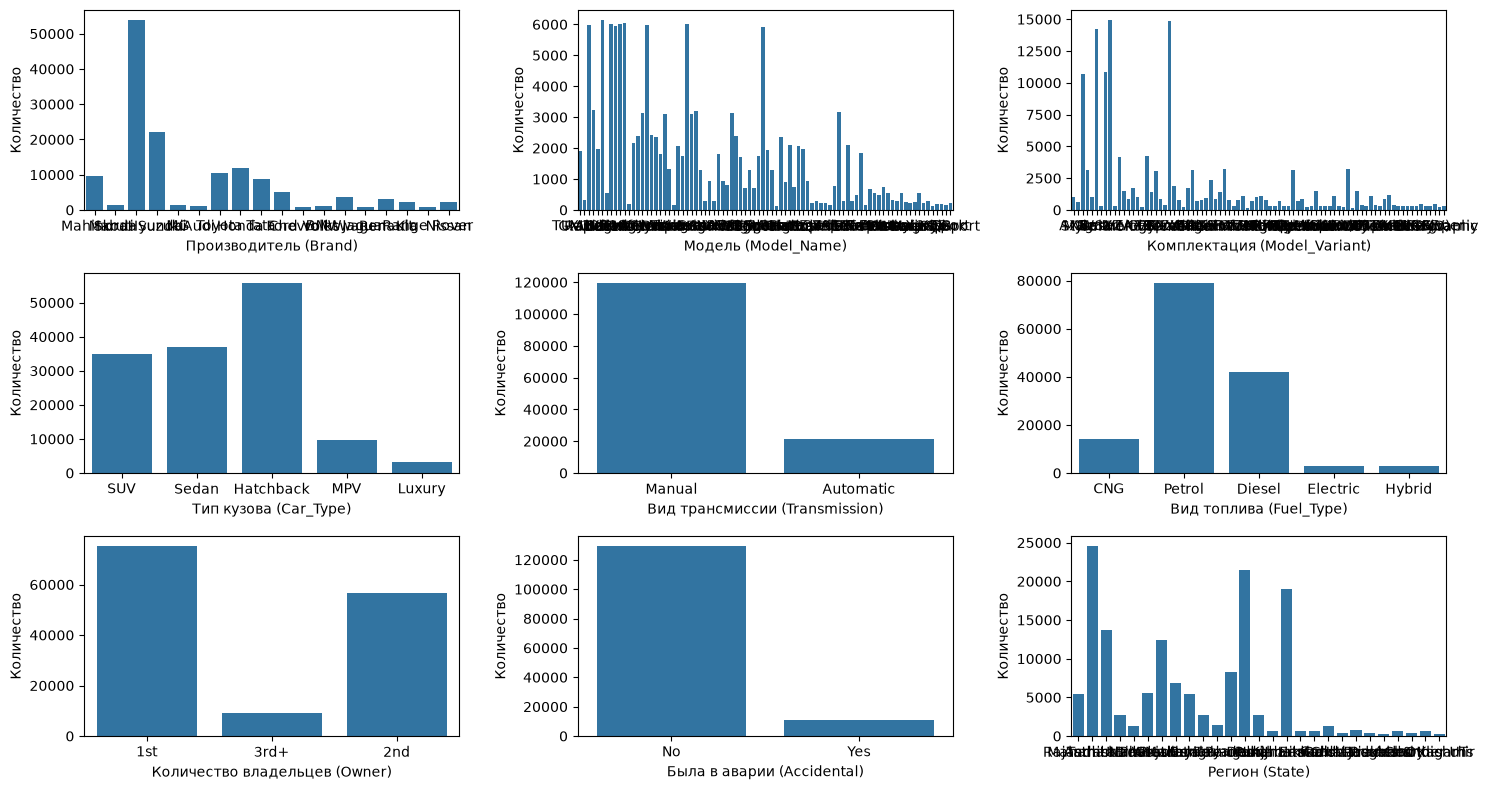

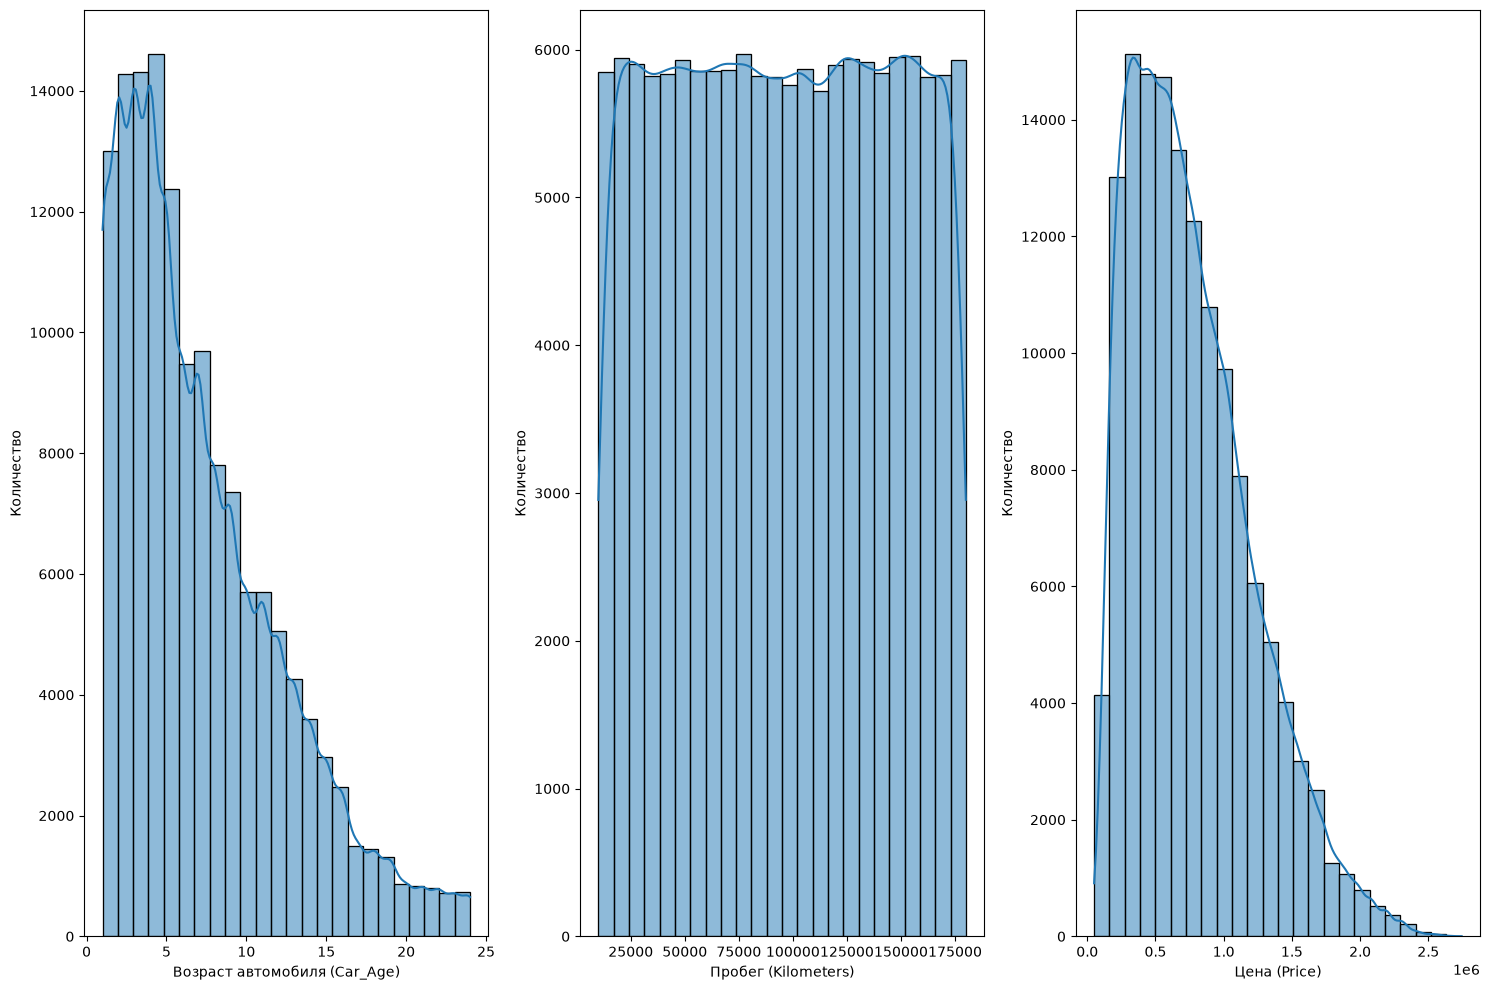

In [8]:

categorical_columns = [ 
    ("Brand", "Производитель"),
    ("Model_Name", "Модель"),
    ("Model_Variant", "Комплектация"),
    ("Car_Type", "Тип кузова"),    
    ("Transmission", "Вид трансмиссии"),
    ("Fuel_Type", "Вид топлива"),
    ("Owner", "Количество владельцев"),
    ("Accidental", "Была в аварии"),
    ("State", "Регион"),
]

numerical_columns = [
    ("Car_Age", "Возраст автомобиля"),
    ("Kilometers", "Пробег"),
    ("Price", "Цена"),
]


fig, axes = plt.subplots(3, 3)
fig.set_size_inches(15, 8)
axes = axes.flatten()
for index, column in enumerate(categorical_columns):
    sns.countplot(data=df, x=column[0], ax=axes[index])
    axes[index].set_xlabel(f"{column[1]} ({column[0]})")
    axes[index].set_ylabel("Количество")
fig.tight_layout()

fig, axes = plt.subplots(1, 3)
fig.set_size_inches(15,10)
axes = axes.flatten()
for index, column in enumerate(numerical_columns):
    sns.histplot(data=df, x=column[0], kde=True, bins=24, ax=axes[index])
    axes[index].set_xlabel(f"{column[1]} ({column[0]})")
    axes[index].set_ylabel("Количество")
fig.tight_layout()

Некоторые графики с категориями получились немного смазанными из-за большого количества категорий. 

Тем не менее можно заметить некоторые интересные закономерности в данных: 

- Распределение пробега автомобилей равномерное.
- Распределение цены и возраста автомобиля похоже Гамма-распределение, хотя как уже наверняка отмечалось на лекциях, любое распределение с одним куполом, определённое на положительных значениях, скорее всего будет неплохо описываться гамма-распределением.

<b>Опишем основные виды столбцов для их последующего преобразования:</b>

In [9]:
from sklearn.preprocessing import TargetEncoder, OrdinalEncoder, OneHotEncoder, LabelEncoder, LabelBinarizer, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

# Категориальные признаки с большим количеством значений
categorical_big_cols = ['Brand', 'Model_Name', 'Model_Variant']

# Ординальный признак и порядок значений
ordinal_columns = ['Owner']
ordinals_order = [["1st", "2nd", "3rd+"]]

# Категориальные столбцы
categorical_columns = ['Car_Type', 'Transmission', 'Fuel_Type', 'State', 'Accidental']

numerical_columns = ["Kilometers", "Car_Age"]


## Первый вариант кодирования категориальных признаков

Там, откуда взят набор данных многие пользователи применяют следующее преобразование данных:

In [10]:
# Encode categorical features
cat_cols = ['Brand', 'Model_Name', 'Model_Variant', 'Car_Type',
            'Transmission', 'Fuel_Type', 'Owner', 'State', 'Accidental']

X_train_transformed = X_train.copy()
X_test_transformed = X_test.copy()
le = LabelEncoder()
for col in cat_cols:
    X_train_transformed[col] = le.fit_transform(X_train_transformed[col])
    X_test_transformed[col] = le.transform(X_test_transformed[col])

Что в этом плохого? 

А то, что все категориальные столбы просто преобразуются в числа от 0 до {количества категорий}-1.

Но проблема в том, что линейная регрессия строит именно линейную зависимость, а при таком представлении никакой линейной зависимости от данных явно нет. Зато полученные данные выглядят красиво. Всего 11 столбцов и всё имеет числовой вид:

In [11]:
X_train_transformed

,Brand,Model_Name,Model_Variant,Car_Type,Transmission,Fuel_Type,Kilometers,Owner,State,Accidental,Car_Age
62830,5,83,46,0,1,1,145257,1,26,0,2
116540,13,38,41,3,1,0,132864,1,5,0,1
104188,15,67,78,4,1,4,152624,1,11,0,7
14893,9,13,66,3,1,1,169510,1,23,0,1
101951,10,16,8,0,1,1,170482,2,5,0,10
...,...,...,...,...,...,...,...,...,...,...,...
70266,5,82,46,0,0,4,15238,1,22,0,11
23461,5,82,6,0,1,4,164745,2,5,0,12
17844,3,29,60,4,1,1,101915,2,13,0,14
100409,15,5,78,0,0,4,171969,1,12,0,3


In [12]:
# Cтандартизация признаков
stand_scaler = StandardScaler()
X_train_transformed = stand_scaler.fit_transform(X_train_transformed)
X_test_transformed = stand_scaler.transform(X_test_transformed)

Такие данные плохо подойдут для применения линейной регрессии, зато хорошо подойдут для <b>деревьев принятия решений</b>. Пока подробно рассматривать это семейство моделей машинного обучения не будем, но мы рассмотрим её на нашем курсе позже, а пока просто применим готовую реализацию.

In [13]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor

models = {
    "Linear Regression": LinearRegression(n_jobs=-1),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    # Варианты решающих деревьев
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=50, random_state=537),
    "Random Forest": RandomForestRegressor(n_estimators=30, random_state=537),
    "AdaBoost": AdaBoostRegressor(n_estimators=50, random_state=537),
}

results = {}
for name, model in models.items():
    model.fit(X_train_transformed, Y_train)
    Y_train_pred = model.predict(X_train_transformed)
    Y_test_pred = model.predict(X_test_transformed)
    mse = root_mean_squared_error(Y_test, Y_test_pred)
    r2 = r2_score(Y_test, Y_test_pred)
    r2_train = r2_score(Y_train, Y_train_pred)
    results[name] = {"RMSE": mse, "R2 Score Train": r2_train, "R2 Score": r2}

results_df = pd.DataFrame(results).T.sort_values(by="R2 Score", ascending=False)
results_df 

,RMSE,R2 Score Train,R2 Score
Gradient Boosting,363915.693828,0.318018,0.321927
AdaBoost,371921.403435,0.287453,0.291765
Random Forest,382092.408283,0.887577,0.252499
Ridge Regression,382331.169707,0.249276,0.251565
Linear Regression,382331.184323,0.249276,0.251565
Lasso Regression,382331.193141,0.249276,0.251565


Как мы видим, на таких данных решающие деревья и правда обходят методы линейной регрессии, правда результаты тоже не самые впечатляющие. Разброс в 300000 при ценах около миллиона не слишком воодушевляют.

Теперь же попробуем более качественно подготовить признаки.

## Второй вариант кодирования признаков

In [14]:

tranformer = ColumnTransformer(transformers=[
    ("categorical", OneHotEncoder(drop="first"), categorical_columns),
    ("cat", OneHotEncoder(drop="first"), categorical_big_cols),
    ("ordinal", OrdinalEncoder(categories=ordinals_order), ordinal_columns),
    ("numeric", StandardScaler(), numerical_columns),
],
remainder="drop")# Остальные столбцы отбрасываются

In [15]:
X_train_transformed = tranformer.fit_transform(X_train)
X_test_transformed = tranformer.transform(X_test)

In [16]:
X_train_transformed

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 999122 stored elements and shape (112723, 220)>

Теперь в преобразованных данных будет уже не 11 столбцов, а 220, зато они позволят обучить линейные модели. Мы исключим Решающие деревья. Из-за большого количества признаков их обучение займёт слишком много времени, а более качественных результатов на решающих деревьях мы не получим.

In [17]:
Y_test_transformed = Y_test
Y_train_transformed = Y_train

In [18]:
models = {
    "Linear Regression": LinearRegression(n_jobs=-1),
    "Lasso Regression": Lasso(),
    "Ridge Regression": Ridge(),
}

results = {}
for name, model in models.items():
    model.fit(X_train_transformed, Y_train_transformed)
    
    Y_train_pred = model.predict(X_train_transformed)
    Y_test_pred = model.predict(X_test_transformed)
    
    mse = root_mean_squared_error(Y_test_transformed, Y_test_pred)
    r2 = r2_score(Y_test_transformed, Y_test_pred)
    r2_train = r2_score(Y_train_transformed, Y_train_pred)
    
    results[name] = {"RMSE": mse, "R2 Score Train": r2_train, "R2 Score": r2}

results_df = pd.DataFrame(results).T.sort_values(by="R2 Score", ascending=False)
results_df 

,RMSE,R2 Score Train,R2 Score
Lasso Regression,376432.060708,0.277344,0.274482
Ridge Regression,376434.342939,0.277344,0.274473
Linear Regression,376436.677669,0.277345,0.274464


И так мы получили снова не впечатляющий результат, но это уже лучше.

Иногда полезно посмотреть на разброс настоящих значений и предсказанных моделью. По получаемой форме можно также оценить работу модели и найти некоторые проблемы. По оси X мы отобразили предсказанные значения, а по оси Y действительные. 

В идеале мы бы хотели увидеть между ними линейную зависимость. 

Что сразу бросается в глаза - иногда модель предсказывает отрицательные значения. Но цена не может быть отрицательной, это хотелось бы как-то исправить.  

Также оказывается, что модель для разных цен ошибается по разному чем больше предсказание модели, тем больше разброс действительных значений.

Но важно заметить, что получаемое облако всё-же довольно вытянутое, то есть у модели что-то получается предсказывать, но плохо.

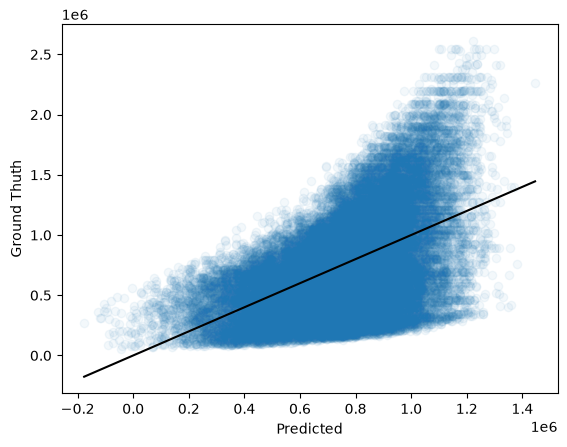

In [19]:

plt.scatter(Y_test_pred, Y_test, alpha=0.05)
plt.xlabel("Predicted")
plt.ylabel("Ground Thuth")


t = np.linspace(Y_test_pred.min(), Y_test_pred.max(),100)

plt.plot(t,t,color="black")

Распределение ошибок. Оно имеет колоколообразное распределение, но оно сильно скошено.

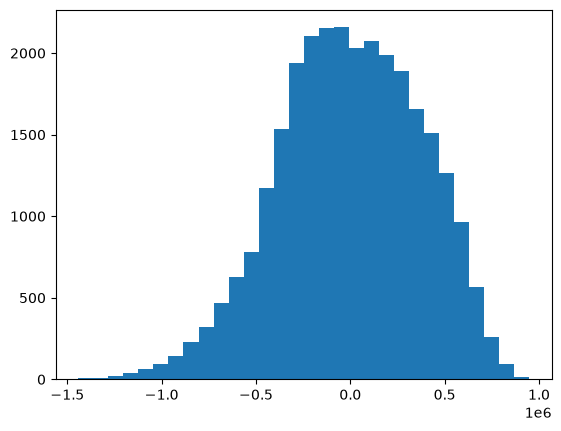

In [20]:
plt.hist(Y_test_pred - Y_test_transformed, bins = 30)
plt.show()

## Логарифмирование целевой переменной

Описанная проблема того, что целевая переменная имеет положительные значения, а модель может предсказывать любые,  является довольно распространённой. Такие данные встречаются очень часто. 

Касательно цен, зарплат и всего, что связано с деньгами добавляется ещё другое свойство: Шум, накладываемый на данные зависит от значения целевой переменной. 

Получается, что просто невозможно обучить модель, которая предсказывала бы цену с фиксированным разбросом, потому что сам шум в данных не фиксированный.

Принято для цен извлекать логарифм и ошибку тоже считать от логарифма цен. Это переводит ошибку, зависимую от значения в фиксированную ошибку.

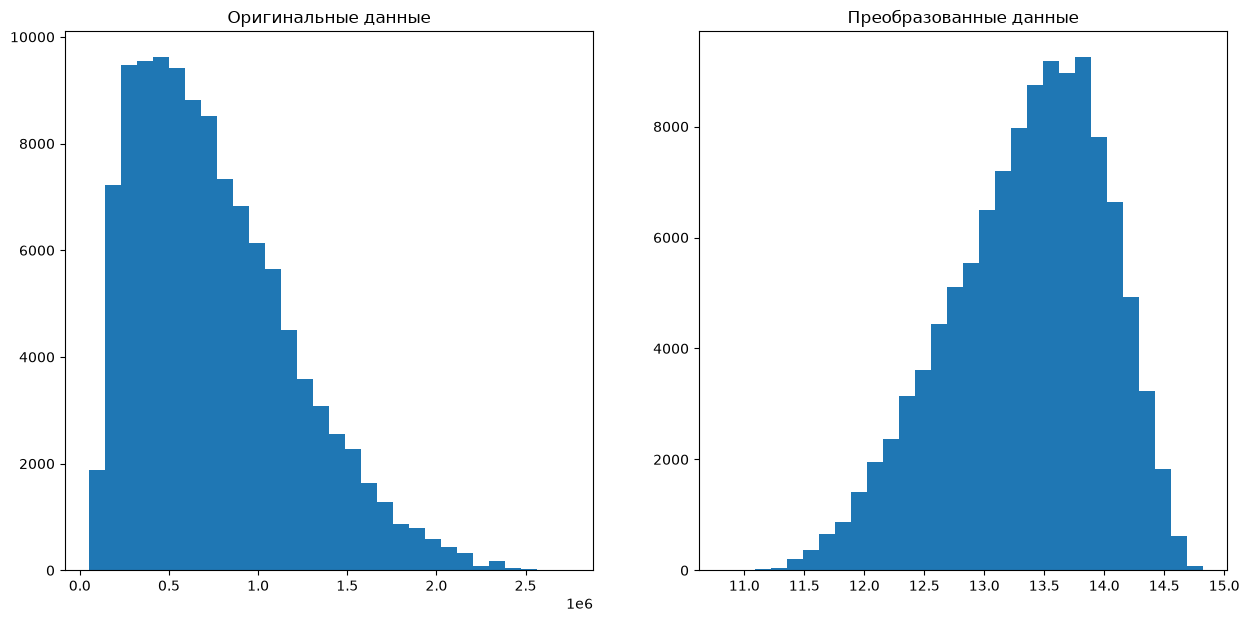

In [21]:
Y_train_transformed = np.log(Y_train)
Y_test_transformed = np.log(Y_test)

plt.subplot(121)
plt.hist(Y_train, bins=30)
plt.title("Оригинальные данные")
plt.subplot(122)
plt.hist(Y_train_transformed, bins=30)
plt.title("Преобразованные данные")
plt.gcf().set_size_inches(15,7)
plt.show()

Теперь обучим модели и оценим ошибку с помощью метрики MAPE. Важно не забывать, что метрики мы хотим посчитать не для логарифма целевой переменной, а всё же для настоящей целевой переменной.

In [22]:
from sklearn.preprocessing import PolynomialFeatures
models = {
    "Linear Regression": LinearRegression(n_jobs=-1),
    "Lasso Regression": Lasso(alpha=0.01),
    "Ridge Regression": Ridge(alpha=0.01),
    "poly": make_pipeline(PolynomialFeatures(degree=2), Ridge(alpha=1000)), # Большой коэффициент регуляризации для предотвращения переобучения
}   

results = {}
for name, model in models.items():
    model.fit(X_train_transformed, Y_train_transformed)
    
    Y_train_pred = model.predict(X_train_transformed)
    Y_test_pred = model.predict(X_test_transformed)

    mse = root_mean_squared_error(Y_test_transformed, Y_test_pred)
    r2 = r2_score(Y_test_transformed, Y_test_pred)
    r2_train = r2_score(Y_train_transformed, Y_train_pred)
    
    results[name] = {"RMSE": mse, "R2 Score Train": r2_train, "R2 Score": r2}

results_df = pd.DataFrame(results).T.sort_values(by="R2 Score", ascending=False)
results_df 

,RMSE,R2 Score Train,R2 Score
poly,0.551687,0.279093,0.271626
Linear Regression,0.557765,0.258236,0.255488
Ridge Regression,0.557768,0.258235,0.255481
Lasso Regression,0.566842,0.231149,0.231059


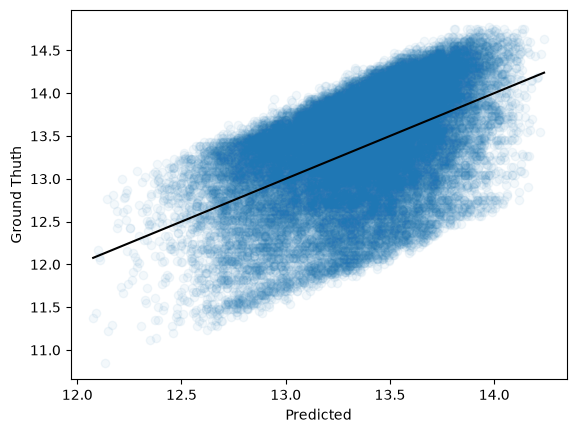

In [23]:
plt.scatter(Y_test_pred,Y_test_transformed,  alpha=0.05)
plt.xlabel("Predicted")
plt.ylabel("Ground Thuth")


t = np.linspace(Y_test_pred.min(), Y_test_pred.max(),100)

plt.plot(t,t,color="black")

# Домашнее задание


Попробуйте улучшить результаты обучения модели. 
- Поменяйте коэффициент регуляризации
- Измените методы регуляризации
- Попробуйте другие методы подготовки данных (к примеру, TargetEncoding)
- Извлеките полиномиальные признаки
- Удалите категории (замените на "другое"), имеющие малое количество объектов


---
# Решение домашнего задания

Цель — улучшить результат последней модели (логарифм цены, one-hot кодирование, `Ridge(alpha=0.01)`, $R^2\approx0.255$ на логарифме цены).

Чтобы не подбирать гиперпараметры по тестовой выборке, отделяю от обучающей выборки валидационную (20%). Все решения принимаю по валидации, а тест считаю один раз в конце. Метрики:
- $R^2$ и RMSE для логарифма цены (то, что оптимизирует модель);
- MAPE и $R^2$ для самой цены (после `exp`), т.к. в итоге интересна именно цена.

In [24]:
import json, time, warnings
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import SplineTransformer, PolynomialFeatures
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.ensemble import HistGradientBoostingRegressor
warnings.filterwarnings("ignore")
RESULTS = {}

X_tr, X_val, y_tr_log, y_val_log = train_test_split(X_train, np.log(Y_train), test_size=0.2, random_state=0)
y_te_log = np.log(Y_test)
owner_order = [["1st", "2nd", "3rd+"]]
num_cols = ["Kilometers", "Car_Age"]

def metrics(model, X, y_log):
    p = model.predict(X)
    return {"R2 log": r2_score(y_log, p), "RMSE log": root_mean_squared_error(y_log, p),
            "MAPE цены": mean_absolute_percentage_error(np.exp(y_log), np.exp(p)),
            "R2 цены": r2_score(np.exp(y_log), np.exp(p))}

experiments = []
def run(name, transformer, model, group):
    t0 = time.time()
    pipe = make_pipeline(transformer, model).fit(X_tr, y_tr_log)
    m = {"эксперимент": name, "группа": group, **{f"{k} (вал.)": v for k, v in metrics(pipe, X_val, y_val_log).items()},
         "время, с": time.time() - t0}
    experiments.append(m)
    print(f"{name:55s} R2 log (вал.) = {m['R2 log (вал.)']:.4f}   MAPE = {m['MAPE цены (вал.)']:.3f}")

def base_transformer(big_encoder=None, cat_encoder=None, numeric=None, extra=()):
    return ColumnTransformer([
        ("categorical", cat_encoder or OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_columns),
        ("big", big_encoder or OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_big_cols),
        ("ordinal", OrdinalEncoder(categories=owner_order), ordinal_columns),
        ("numeric", numeric or StandardScaler(), num_cols),
        *extra,
    ], remainder="drop")

run("Базовая модель с занятия: OneHot + Ridge(0.01)", base_transformer(), Ridge(alpha=0.01), "база")

Базовая модель с занятия: OneHot + Ridge(0.01)          R2 log (вал.) = 0.2592   MAPE = 0.547


## 1. Коэффициент регуляризации

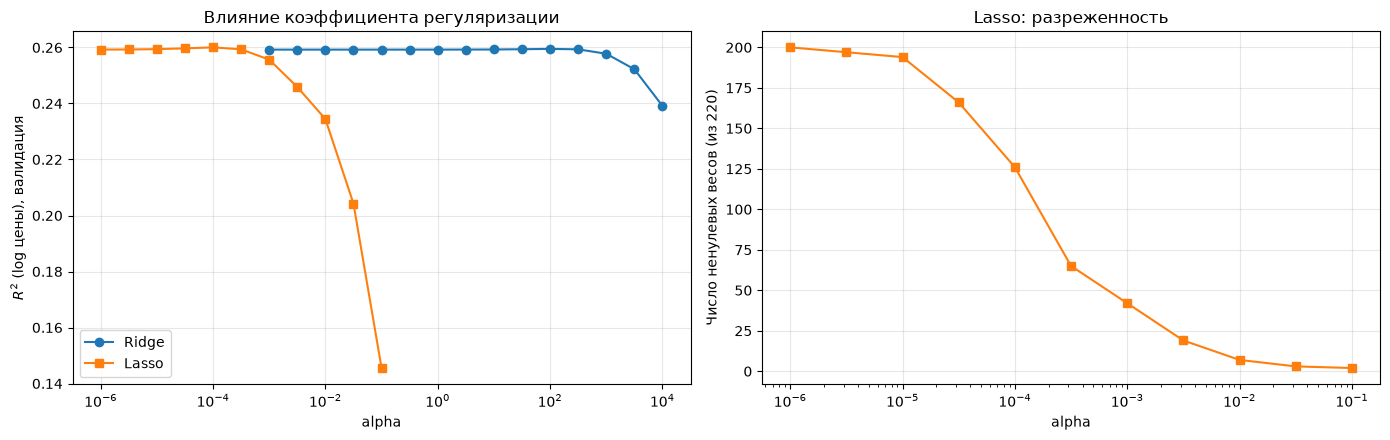

Ridge: лучший alpha = 100, R2 = 0.2595; при alpha=1e-3: 0.2592
Lasso: лучший alpha = 0.0001, R2 = 0.2600
Lasso, ненулевых весов: {'1e-06': 200, '3e-06': 197, '1e-05': 194, '3e-05': 166, '1e-04': 126, '3e-04': 65, '1e-03': 42, '3e-03': 19, '1e-02': 7, '3e-02': 3, '1e-01': 2}


In [25]:
alphas_ridge = np.logspace(-3, 4, 15)
alphas_lasso = np.logspace(-6, -1, 11)
Xt_tr = base_transformer().fit(X_tr, y_tr_log)
A_tr, A_val = Xt_tr.transform(X_tr), Xt_tr.transform(X_val)
ridge_curve = [r2_score(y_val_log, Ridge(alpha=a).fit(A_tr, y_tr_log).predict(A_val)) for a in alphas_ridge]
lasso_curve, lasso_nz = [], []
for a in alphas_lasso:
    l = Lasso(alpha=a, max_iter=5000).fit(A_tr, y_tr_log)
    lasso_curve.append(r2_score(y_val_log, l.predict(A_val))); lasso_nz.append(int(np.sum(l.coef_ != 0)))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(alphas_ridge, ridge_curve, "o-", label="Ridge")
ax[0].plot(alphas_lasso, lasso_curve, "s-", label="Lasso")
ax[0].set_xscale("log"); ax[0].set_xlabel("alpha"); ax[0].set_ylabel("$R^2$ (log цены), валидация")
ax[0].set_title("Влияние коэффициента регуляризации"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(alphas_lasso, lasso_nz, "s-", color="tab:orange")
ax[1].set_xscale("log"); ax[1].set_xlabel("alpha"); ax[1].set_ylabel("Число ненулевых весов (из %d)" % A_tr.shape[1])
ax[1].set_title("Lasso: разреженность"); ax[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/car_alpha.png", dpi=150, bbox_inches="tight"); plt.show()

best_ridge_alpha = alphas_ridge[int(np.argmax(ridge_curve))]
best_lasso_alpha = alphas_lasso[int(np.argmax(lasso_curve))]
print(f"Ridge: лучший alpha = {best_ridge_alpha:.3g}, R2 = {max(ridge_curve):.4f}; при alpha=1e-3: {ridge_curve[0]:.4f}")
print(f"Lasso: лучший alpha = {best_lasso_alpha:.3g}, R2 = {max(lasso_curve):.4f}")
print("Lasso, ненулевых весов:", dict(zip([f'{a:.0e}' for a in alphas_lasso], lasso_nz)))
RESULTS["alpha"] = {"ridge_best": float(best_ridge_alpha), "ridge_best_r2": float(max(ridge_curve)),
                    "ridge_min_r2": float(min(ridge_curve)), "lasso_best": float(best_lasso_alpha),
                    "lasso_best_r2": float(max(lasso_curve)), "n_features": int(A_tr.shape[1]),
                    "lasso_nz": dict(zip([f'{a:.0e}' for a in alphas_lasso], lasso_nz)),
                    "lasso_r2": dict(zip([f'{a:.0e}' for a in alphas_lasso], np.round(lasso_curve, 4).tolist()))}

Подбор `alpha` почти ничего не даёт: у Ridge качество практически постоянно вплоть до `alpha≈100` и падает только при очень сильной регуляризации. Причина в соотношении объёма данных и числа признаков: ~90 тысяч объектов на ~220 признаков, переобучаться модели просто не на чем, и регуляризация не нужна. Lasso при сильной регуляризации обнуляет большую часть one-hot признаков (комплектации, модели) и качество падает — это то, что произошло на занятии при `alpha=0.01`.

## 2. Другие методы регуляризации

In [26]:
run(f"Ridge, alpha={best_ridge_alpha:.3g}", base_transformer(), Ridge(alpha=best_ridge_alpha), "регуляризация")
run(f"Lasso, alpha={best_lasso_alpha:.3g}", base_transformer(), Lasso(alpha=best_lasso_alpha, max_iter=5000), "регуляризация")
run("ElasticNet, alpha=1e-4, l1_ratio=0.5", base_transformer(), ElasticNet(alpha=1e-4, l1_ratio=0.5, max_iter=5000), "регуляризация")

Ridge, alpha=100                                        R2 log (вал.) = 0.2595   MAPE = 0.547


Lasso, alpha=0.0001                                     R2 log (вал.) = 0.2600   MAPE = 0.547


ElasticNet, alpha=1e-4, l1_ratio=0.5                    R2 log (вал.) = 0.2599   MAPE = 0.547


Все три вида регуляризации при правильном `alpha` дают одинаковый результат — по той же причине: регуляризация борется с переобучением, а здесь его нет.

## 3. Другие методы подготовки данных: TargetEncoding

Заменяю one-hot кодирование «больших» категориальных признаков (производитель, модель, комплектация — 18/84/82 значения) на `TargetEncoder` (среднее значение целевой переменной по категории со сглаживанием и внутренней кросс-валидацией, чтобы не было утечки). Отдельно пробую target-кодирование для региона.

In [27]:
run("TargetEncoder для Brand/Model/Variant", base_transformer(big_encoder=TargetEncoder(random_state=0)), Ridge(1.0), "кодирование")
run("TargetEncoder для всех категорий",
    base_transformer(big_encoder=TargetEncoder(random_state=0), cat_encoder=TargetEncoder(random_state=0)), Ridge(1.0), "кодирование")
run("OneHot для Owner вместо Ordinal",
    ColumnTransformer([("c", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_columns + ordinal_columns),
                       ("b", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_big_cols),
                       ("n", StandardScaler(), num_cols)]), Ridge(1.0), "кодирование")

TargetEncoder для Brand/Model/Variant                   R2 log (вал.) = 0.2563   MAPE = 0.548


TargetEncoder для всех категорий                        R2 log (вал.) = 0.2560   MAPE = 0.548


OneHot для Owner вместо Ordinal                         R2 log (вал.) = 0.2599   MAPE = 0.547


TargetEncoding не помог и даже чуть ухудшил результат. При one-hot кодировании каждая категория получает свой вес, и данных для этого достаточно (на каждую категорию сотни-тысячи объектов). TargetEncoder сжимает категорию до одного числа — это полезно, когда категорий очень много и объектов на каждую мало, а здесь это просто потеря информации. Кодирование числа владельцев one-hot вместо порядкового тоже ничего не меняет — зависимость от него почти линейная.

## 4. Полиномиальные и нелинейные признаки

Посмотрю, как средний логарифм цены зависит от числовых признаков.

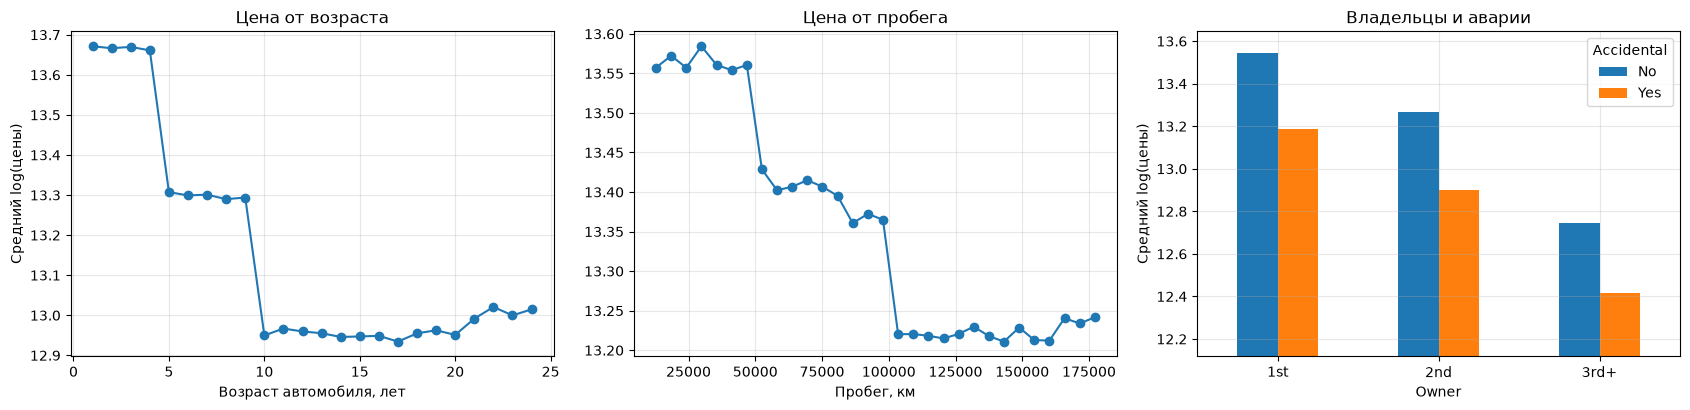

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
tmp = X_train.assign(log_price=np.log(Y_train))
g = tmp.groupby("Car_Age")["log_price"].agg(["mean", "count"])
ax[0].plot(g.index, g["mean"], "o-"); ax[0].set_xlabel("Возраст автомобиля, лет"); ax[0].set_ylabel("Средний log(цены)")
ax[0].set_title("Цена от возраста")
km_bins = pd.cut(tmp["Kilometers"], 30)
g2 = tmp.groupby(km_bins, observed=True)["log_price"].mean()
ax[1].plot([iv.mid for iv in g2.index], g2.values, "o-"); ax[1].set_xlabel("Пробег, км"); ax[1].set_title("Цена от пробега")
g3 = tmp.groupby(["Owner", "Accidental"])["log_price"].mean().unstack()
g3.plot(kind="bar", ax=ax[2], rot=0); ax[2].set_ylabel("Средний log(цены)"); ax[2].set_title("Владельцы и аварии")
ax[2].set_ylim(g3.values.min() - 0.3, g3.values.max() + 0.1)
for a in ax: a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/car_numeric.png", dpi=150, bbox_inches="tight"); plt.show()

Зависимость от возраста явно нелинейная (и немонотонная на краях), от пробега — тоже не прямая линия. Значит, линейная модель на этих признаках недообучается, и нелинейные признаки должны помочь. Пробую:
- полиномиальные признаки степени 2–3 для числовых столбцов;
- сплайны (кусочно-полиномиальные базисные функции — по смыслу те же «локальные признаки» из прошлой практики);
- возраст как категориальный признак (24 значения — каждому возрасту свой вес);
- попарные взаимодействия числовых и важных категориальных признаков (возраст × пробег × владельцы × аварии).

In [29]:
poly_num = lambda d: make_pipeline(StandardScaler(), PolynomialFeatures(d, include_bias=False))
run("Полиномы степени 2 для Kilometers, Car_Age", base_transformer(numeric=poly_num(2)), Ridge(1.0), "нелинейность")
run("Полиномы степени 3 для Kilometers, Car_Age", base_transformer(numeric=poly_num(3)), Ridge(1.0), "нелинейность")
run("Сплайны (8 узлов) для Kilometers, Car_Age", base_transformer(numeric=SplineTransformer(n_knots=8)), Ridge(1.0), "нелинейность")

age_cat = ColumnTransformer([
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_columns + ["Car_Age"]),
    ("big", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_big_cols),
    ("ordinal", OrdinalEncoder(categories=owner_order), ordinal_columns),
    ("km", SplineTransformer(n_knots=8), ["Kilometers"]),
])
run("Возраст one-hot + сплайны для пробега", age_cat, Ridge(1.0), "нелинейность")

inter = ColumnTransformer([
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_columns + ["Car_Age"]),
    ("big", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_big_cols),
    ("km", SplineTransformer(n_knots=8), ["Kilometers"]),
    ("inter", make_pipeline(ColumnTransformer([("o", OrdinalEncoder(categories=owner_order), ordinal_columns),
                                               ("a", OrdinalEncoder(categories=[["No", "Yes"]]), ["Accidental"]),
                                               ("n", StandardScaler(), num_cols)]),
                            PolynomialFeatures(2, include_bias=False)), ordinal_columns + ["Accidental"] + num_cols),
])
run("+ попарные взаимодействия (возраст, пробег, владельцы, аварии)", inter, Ridge(1.0), "нелинейность")

Полиномы степени 2 для Kilometers, Car_Age              R2 log (вал.) = 0.2741   MAPE = 0.543


Полиномы степени 3 для Kilometers, Car_Age              R2 log (вал.) = 0.2750   MAPE = 0.543


Сплайны (8 узлов) для Kilometers, Car_Age               R2 log (вал.) = 0.2813   MAPE = 0.541


Возраст one-hot + сплайны для пробега                   R2 log (вал.) = 0.2918   MAPE = 0.538


+ попарные взаимодействия (возраст, пробег, владельцы, аварии) R2 log (вал.) = 0.2921   MAPE = 0.538


## 5. Объединение редких категорий в «другое»

У `Model_Name` и `Model_Variant` много значений. Посмотрю, сколько объектов в самых редких категориях, и попробую объединять категории с числом объектов меньше порога (`OneHotEncoder(min_frequency=k)` делает ровно это: редкие категории идут в общую категорию «infrequent»).

In [30]:
for c in categorical_big_cols + ["State"]:
    vc = X_train[c].value_counts()
    print(f"{c:14s}: {len(vc):3d} категорий, min = {vc.min():5d}, 5 самых редких: {dict(vc.tail(5))}")

rare_rows = []
for k in [1, 100, 500, 1000, 2000, 5000]:
    tr_k = ColumnTransformer([
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_columns + ["Car_Age"]),
        ("big", OneHotEncoder(min_frequency=k, handle_unknown="infrequent_if_exist"), categorical_big_cols),
        ("km", SplineTransformer(n_knots=8), ["Kilometers"]),
        ("ordinal", OrdinalEncoder(categories=owner_order), ordinal_columns),
    ])
    pipe = make_pipeline(tr_k, Ridge(1.0)).fit(X_tr, y_tr_log)
    n_feat = pipe[0].transform(X_val.iloc[:5]).shape[1]
    rare_rows.append({"min_frequency": k, "признаков": n_feat, "R2 log (вал.)": r2_score(y_val_log, pipe.predict(X_val))})
rare_df = pd.DataFrame(rare_rows)
RESULTS["rare"] = rare_df.round(4).to_dict(orient="records")
print(rare_df.round(4).to_string(index=False))
run("Возраст one-hot + сплайны + редкие категории (<1000) в «другое»",
    ColumnTransformer([
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_columns + ["Car_Age"]),
        ("big", OneHotEncoder(min_frequency=1000, handle_unknown="infrequent_if_exist"), categorical_big_cols),
        ("km", SplineTransformer(n_knots=8), ["Kilometers"]),
        ("ordinal", OrdinalEncoder(categories=owner_order), ordinal_columns),
    ]), Ridge(1.0), "редкие категории")
run("Итог: возраст one-hot + сплайны + взаимодействия + редкие (<2000)",
    ColumnTransformer([
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_columns + ["Car_Age"]),
        ("big", OneHotEncoder(min_frequency=2000, handle_unknown="infrequent_if_exist"), categorical_big_cols),
        ("km", SplineTransformer(n_knots=8), ["Kilometers"]),
        ("inter", make_pipeline(ColumnTransformer([("o", OrdinalEncoder(categories=owner_order), ordinal_columns),
                                                   ("a", OrdinalEncoder(categories=[["No", "Yes"]]), ["Accidental"]),
                                                   ("n", StandardScaler(), num_cols)]),
                                PolynomialFeatures(2, include_bias=False)), ordinal_columns + ["Accidental"] + num_cols),
    ]), Ridge(1.0), "итог")

Brand         :  18 категорий, min =   598, 5 самых редких: {'BMW': np.int64(845), 'Audi': np.int64(802), 'Range Rover': np.int64(734), 'Jaguar': np.int64(715), 'Chevrolet': np.int64(598)}
Model_Name    :  84 категорий, min =   109, 5 самых редких: {'Cruze': np.int64(130), 'Spark': np.int64(126), 'Sail': np.int64(118), 'Tavera': np.int64(115), 'Beat': np.int64(109)}
Model_Variant :  82 категорий, min =   129, 5 самых редких: {'R-Dynamic': np.int64(177), 'Portfolio': np.int64(175), 'LTZ': np.int64(159), 'LS': np.int64(146), 'LT': np.int64(129)}
State         :  27 категорий, min =   217, 5 самых редких: {'Jammu & Kashmir': np.int64(326), 'Himachal Pradesh': np.int64(313), 'Uttarakhand': np.int64(288), 'Other UTs': np.int64(249), 'Puducherry': np.int64(217)}


 min_frequency  признаков  R2 log (вал.)
             1        254         0.2918
           100        252         0.2918
           500        176         0.2926
          1000        138         0.2927
          2000        104         0.2930
          5000         84         0.2933


Возраст one-hot + сплайны + редкие категории (<1000) в «другое» R2 log (вал.) = 0.2927   MAPE = 0.538


Итог: возраст one-hot + сплайны + взаимодействия + редкие (<2000) R2 log (вал.) = 0.2933   MAPE = 0.537


Даже самые редкие категории содержат больше сотни объектов, поэтому при маленьком пороге ничего не меняется. Но, что интересно, при увеличении порога качество немного, но стабильно растёт — вплоть до порога 5000, когда от 254 признаков остаётся 84. Это значит, что веса отдельных моделей и комплектаций в основном подгоняются под шум, и информации о цене в них почти нет (в этом наборе цена слабо зависит от марки и модели). Объединение редких категорий уменьшает число параметров и этот шум. В итоговую модель беру порог 2000.

## 6. Для сравнения: градиентный бустинг

Чтобы понять, есть ли вообще куда расти, обучаю `HistGradientBoostingRegressor` с нативной поддержкой категорий — он сам находит нелинейности и взаимодействия.

In [31]:
def to_cat(X):
    X = X.copy()
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype("category")
    return X
t0 = time.time()
hgb = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=300, random_state=0).fit(to_cat(X_tr), y_tr_log)
m = metrics(hgb, to_cat(X_val), y_val_log)
experiments.append({"эксперимент": "HistGradientBoosting (для сравнения)", "группа": "ориентир",
                    **{f"{k} (вал.)": v for k, v in m.items()}, "время, с": time.time() - t0})
print(f"HistGradientBoosting: R2 log (вал.) = {m['R2 log']:.4f}, MAPE = {m['MAPE цены']:.3f}")

HistGradientBoosting: R2 log (вал.) = 0.2860, MAPE = 0.540


## Итог

                                                                             группа  R2 log (вал.)  RMSE log (вал.)  MAPE цены (вал.)  R2 цены (вал.)
эксперимент                                                                                                                                          
Базовая модель с занятия: OneHot + Ridge(0.01)                                 база         0.2592           0.5587            0.5475          0.2360
Ridge, alpha=100                                                      регуляризация         0.2595           0.5586            0.5474          0.2357
Lasso, alpha=0.0001                                                   регуляризация         0.2600           0.5584            0.5472          0.2365
ElasticNet, alpha=1e-4, l1_ratio=0.5                                  регуляризация         0.2599           0.5585            0.5473          0.2365
TargetEncoder для Brand/Model/Variant                                   кодирование         0.2563  


Тестовая выборка:
                          R2 log  RMSE log  MAPE цены  R2 цены
Базовая модель (занятие)  0.2555    0.5578     0.5471   0.2341
Итоговая модель           0.2915    0.5441     0.5355   0.2827


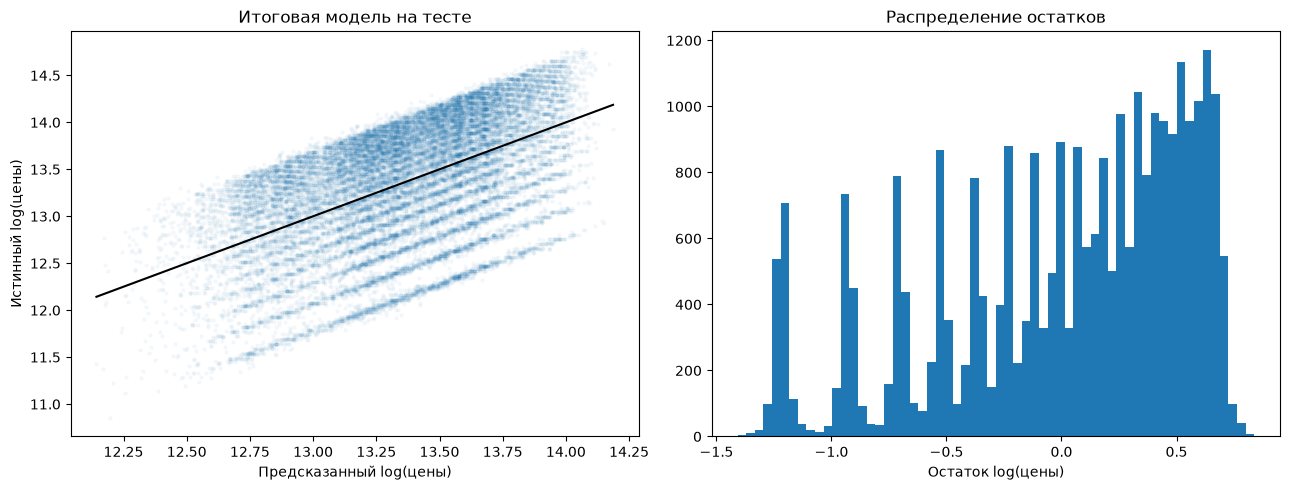

In [32]:
exp_df = pd.DataFrame(experiments).set_index("эксперимент")
display_cols = ["группа", "R2 log (вал.)", "RMSE log (вал.)", "MAPE цены (вал.)", "R2 цены (вал.)"]
print(exp_df[display_cols].round(4).to_string())
RESULTS["experiments"] = exp_df[display_cols].round(4).reset_index().to_dict(orient="records")

# финальная модель: переобучаем на всей обучающей выборке и один раз проверяем на тесте
final_tr = ColumnTransformer([
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_columns + ["Car_Age"]),
    ("big", OneHotEncoder(min_frequency=2000, handle_unknown="infrequent_if_exist"), categorical_big_cols),
    ("km", SplineTransformer(n_knots=8), ["Kilometers"]),
    ("inter", make_pipeline(ColumnTransformer([("o", OrdinalEncoder(categories=owner_order), ordinal_columns),
                                               ("a", OrdinalEncoder(categories=[["No", "Yes"]]), ["Accidental"]),
                                               ("n", StandardScaler(), num_cols)]),
                            PolynomialFeatures(2, include_bias=False)), ordinal_columns + ["Accidental"] + num_cols),
])
final = make_pipeline(final_tr, Ridge(1.0)).fit(X_train, np.log(Y_train))
base_final = make_pipeline(base_transformer(), Ridge(alpha=0.01)).fit(X_train, np.log(Y_train))
test_rows = {"Базовая модель (занятие)": metrics(base_final, X_test, y_te_log), "Итоговая модель": metrics(final, X_test, y_te_log)}
test_df = pd.DataFrame(test_rows).T
RESULTS["test"] = test_df.round(4).reset_index().to_dict(orient="records")
print("\nТестовая выборка:")
print(test_df.round(4))

p = final.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(p, y_te_log, alpha=0.03, s=5); t = np.linspace(p.min(), p.max(), 2); ax[0].plot(t, t, "k")
ax[0].set_xlabel("Предсказанный log(цены)"); ax[0].set_ylabel("Истинный log(цены)"); ax[0].set_title("Итоговая модель на тесте")
ax[1].hist(y_te_log - p, bins=60); ax[1].set_xlabel("Остаток log(цены)"); ax[1].set_title("Распределение остатков")
fig.tight_layout(); fig.savefig("figures/car_final.png", dpi=150, bbox_inches="tight"); plt.show()
with open("figures/results_car.json", "w") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2, default=float)

**Выводы по домашнему заданию.**
- Больше всего помогло учесть **нелинейную зависимость от возраста и пробега** (возраст как категория, сплайны для пробега): $R^2$ на валидации вырос с 0.259 до 0.292. Взаимодействия признаков почти ничего не добавили, объединение редких моделей/комплектаций дало ещё немного.
- Изменение коэффициента и вида регуляризации практически ничего не даёт: признаков ~220 на ~90 тысяч объектов, переобучения нет.
- TargetEncoding не помог: категорий немного, в каждой сотни объектов, и one-hot кодирование не страдает от нехватки данных. Объединение редких категорий, наоборот, немного помогло — из-за того, что марка и модель почти не влияют на цену.
- Даже градиентный бустинг, который сам находит нелинейности и взаимодействия, даёт $R^2pprox0.286$ — не лучше нашей линейной модели с хорошими признаками. Значит, мы близки к потолку для этих данных. Большая часть разброса цен не объясняется имеющимися признаками (похоже, данные частично синтетические: например, средняя цена Range Rover в наборе ниже, чем у Kia). Поэтому абсолютные значения $R^2$ невысокие, и дальнейший рост возможен только за счёт новых признаков, а не модели.